In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("BROKE — Behavioral Analytics Started!")

BROKE — Behavioral Analytics Started!


In [3]:
df = pd.read_csv(
    "../data/processed/cleaned_student_expenses.csv",
    parse_dates=["date"]
)

df.head()

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city,day_of_week,is_weekend,expense_size
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis,Tuesday,False,Medium
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis,Tuesday,False,Medium
2,S001,2026-09-01,Education,39.25,Card,True,676,Tunis,Tuesday,False,Large
3,S001,2026-09-02,Shopping,53.28,Cash,False,676,Tunis,Wednesday,False,Large
4,S001,2026-09-02,Shopping,93.78,Cash,False,676,Tunis,Wednesday,False,Large


In [5]:
print(df.columns.tolist())
print("Students:", df["student_id"].nunique())
print("Transactions:", len(df))

['student_id', 'date', 'category', 'amount_tnd', 'payment_method', 'is_essential', 'monthly_budget', 'city', 'day_of_week', 'is_weekend', 'expense_size']
Students: 100
Transactions: 7565


In [7]:
small_expenses = df[
    df["amount_tnd"] < 10
].copy()

small_expenses.head()

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city,day_of_week,is_weekend,expense_size
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis,Tuesday,False,Medium
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis,Tuesday,False,Medium
8,S001,2026-09-04,Coffee,5.79,Card,False,676,Tunis,Friday,False,Medium
10,S001,2026-09-04,Transport,8.01,Card,True,676,Tunis,Friday,False,Medium
12,S001,2026-09-05,Food,7.31,Card,True,676,Tunis,Saturday,True,Medium


In [9]:
total_spending = df["amount_tnd"].sum()

small_spending = small_expenses["amount_tnd"].sum()

small_percentage = (
    small_spending / total_spending
) * 100

print(f"Total Spending: {total_spending:.2f} TND")
print(f"Small Expenses: {small_spending:.2f} TND")
print(f"Small Expenses Share: {small_percentage:.2f}%")

Total Spending: 163450.47 TND
Small Expenses: 18149.99 TND
Small Expenses Share: 11.10%


In [11]:
small_by_student = (
    small_expenses.groupby("student_id")
    .agg(
        small_expense_total=("amount_tnd", "sum"),
        small_expense_count=("amount_tnd", "count")
    )
    .reset_index()
)

small_by_student.head()

,student_id,small_expense_total,small_expense_count
0,S001,199.43,33
1,S002,171.52,30
2,S003,177.65,32
3,S004,195.88,29
4,S005,138.58,27


In [13]:
student_budgets = (
    df.groupby("student_id")["monthly_budget"]
    .first()
    .reset_index()
)

In [15]:
small_by_student = small_by_student.merge(
    student_budgets,
    on="student_id",
    how="left"
)

In [17]:
df["day_of_week"] = df["date"].dt.day_name()

df["is_weekend"] = (
    df["date"].dt.dayofweek >= 5
)


In [19]:
weekend_spending = (
    df.groupby("is_weekend")["amount_tnd"]
    .sum()
)

weekend_spending

is_weekend
False    120336.85
True      43113.62
Name: amount_tnd, dtype: float64

In [21]:
daily_spending = (
    df.groupby("date")["amount_tnd"]
    .sum()
    .reset_index()
)

daily_spending["is_weekend"] = (
    daily_spending["date"].dt.dayofweek >= 5
)

daily_spending.head()

,date,amount_tnd,is_weekend
0,2026-09-01,5077.67,False
1,2026-09-02,5458.32,False
2,2026-09-03,4788.45,False
3,2026-09-04,5749.69,False
4,2026-09-05,5943.70,True


In [23]:
weekend_average = (
    daily_spending.groupby("is_weekend")["amount_tnd"]
    .mean()
)

weekend_average

is_weekend
False    5469.856818
True     5389.202500
Name: amount_tnd, dtype: float64

In [25]:
weekday_mean = weekend_average.loc[False]
weekend_mean = weekend_average.loc[True]

weekend_effect = (
    (weekend_mean - weekday_mean)
    / weekday_mean
) * 100

print(f"Weekend Effect: {weekend_effect:.2f}%")

Weekend Effect: -1.47%


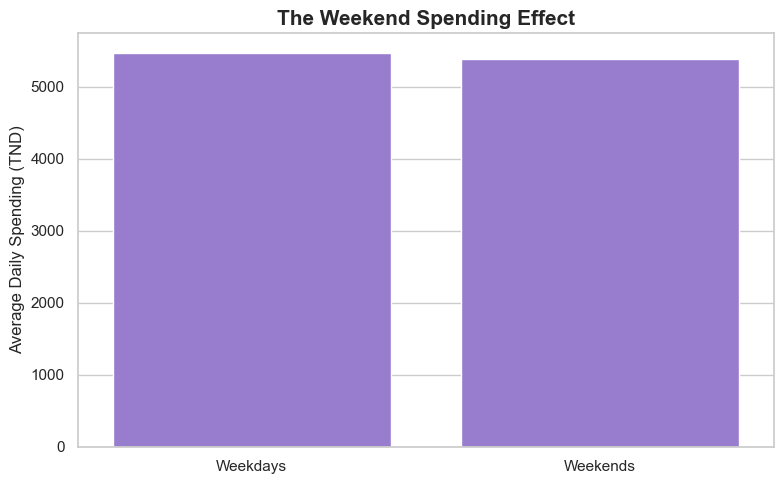

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Weekdays", "Weekends"],
    y=[weekday_mean, weekend_mean],
    color="mediumpurple"
)

plt.title(
    "The Weekend Spending Effect",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Average Daily Spending (TND)")
plt.xlabel("")

plt.tight_layout()
plt.show()

In [29]:
student_daily = (
    df.groupby(["student_id", "date"])["amount_tnd"]
    .sum()
    .reset_index()
)

student_daily.head()

,student_id,date,amount_tnd
0,S001,2026-09-01,56.28
1,S001,2026-09-02,215.18
2,S001,2026-09-03,20.42
3,S001,2026-09-04,74.11
4,S001,2026-09-05,38.38


In [31]:
student_daily = student_daily.sort_values(
    ["student_id", "date"]
)

student_daily["cumulative_spending"] = (
    student_daily.groupby("student_id")["amount_tnd"]
    .cumsum()
)

In [33]:
student_daily = student_daily.merge(
    student_budgets,
    on="student_id",
    how="left"
)

In [35]:
student_daily["budget_used_pct"] = (
    student_daily["cumulative_spending"]
    / student_daily["monthly_budget"]
) * 100

In [37]:
over_budget_days = student_daily[
    student_daily["budget_used_pct"] > 100
]

first_over_budget = (
    over_budget_days.groupby("student_id")["date"]
    .min()
    .reset_index()
)

first_over_budget.rename(
    columns={"date": "first_over_budget_date"},
    inplace=True
)

first_over_budget.head()

,student_id,first_over_budget_date
0,S001,2026-09-11
1,S002,2026-09-10
2,S003,2026-09-05
3,S004,2026-09-09
4,S005,2026-09-10


In [39]:
student_id = "S001"

student_data = student_daily[
    student_daily["student_id"] == student_id
]

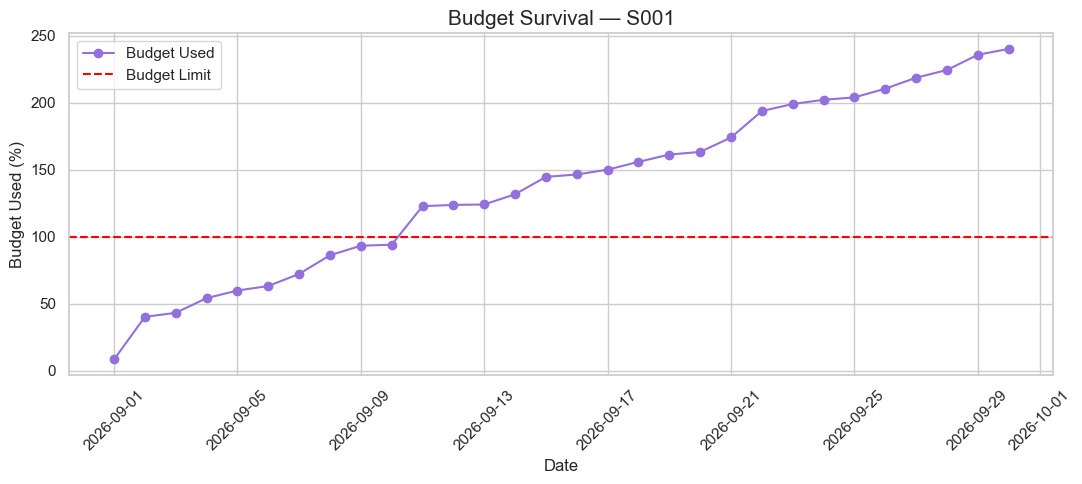

In [41]:
plt.figure(figsize=(11, 5))

plt.plot(
    student_data["date"],
    student_data["budget_used_pct"],
    marker="o",
    color="mediumpurple",
    label="Budget Used"
)

plt.axhline(
    y=100,
    color="red",
    linestyle="--",
    label="Budget Limit"
)

plt.title(
    f"Budget Survival — {student_id}",
    fontsize=15
)

plt.xlabel("Date")
plt.ylabel("Budget Used (%)")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
category_profile = pd.pivot_table(
    df,
    index="student_id",
    columns="category",
    values="amount_tnd",
    aggfunc="sum",
    fill_value=0
)

category_profile.head()

category,Coffee,Education,Entertainment,Food,Shopping,Transport
student_id,,,,,,
S001,63.44,131.70,393.32,126.95,817.64,91.14
S002,51.79,337.57,280.36,189.72,1020.68,46.66
S003,45.06,472.75,283.98,99.54,898.17,68.18
S004,64.50,375.09,399.18,102.51,813.65,52.68
S005,59.33,144.99,210.41,152.74,658.84,45.31


In [45]:
category_shares = (
    category_profile.div(
        category_profile.sum(axis=1),
        axis=0
    ) * 100
)

category_shares.head()

category,Coffee,Education,Entertainment,Food,Shopping,Transport
student_id,,,,,,
S001,3.905947,8.108657,24.216379,7.816204,50.341401,5.611412
S002,2.687904,17.519904,14.550701,9.846480,52.973355,2.421657
S003,2.412619,25.312152,15.204960,5.329607,48.090144,3.650518
S004,3.568248,20.750604,22.083303,5.671024,45.012475,2.914345
S005,4.665702,11.401991,16.546610,12.011450,51.811076,3.563171


In [61]:
def spending_personality(row):

    if row.get("Coffee", 0) >= 25:
        return "Coffee Lover "

    elif row.get("Food", 0) >= 35:
        return "Foodie "

    elif row.get("Shopping", 0) >= 40:
        return "Shopping Enthusiast "

    elif row.get("Entertainment", 0) >= 30:
        return "Entertainment Lover "

    else:
        return "Balanced Spender "

In [63]:
category_shares["personality"] = (
    category_shares.apply(
        spending_personality,
        axis=1
    )
)

In [65]:
category_shares["personality"].value_counts()

personality
Shopping Enthusiast     65
Balanced Spender        34
Entertainment Lover      1
Name: count, dtype: int64

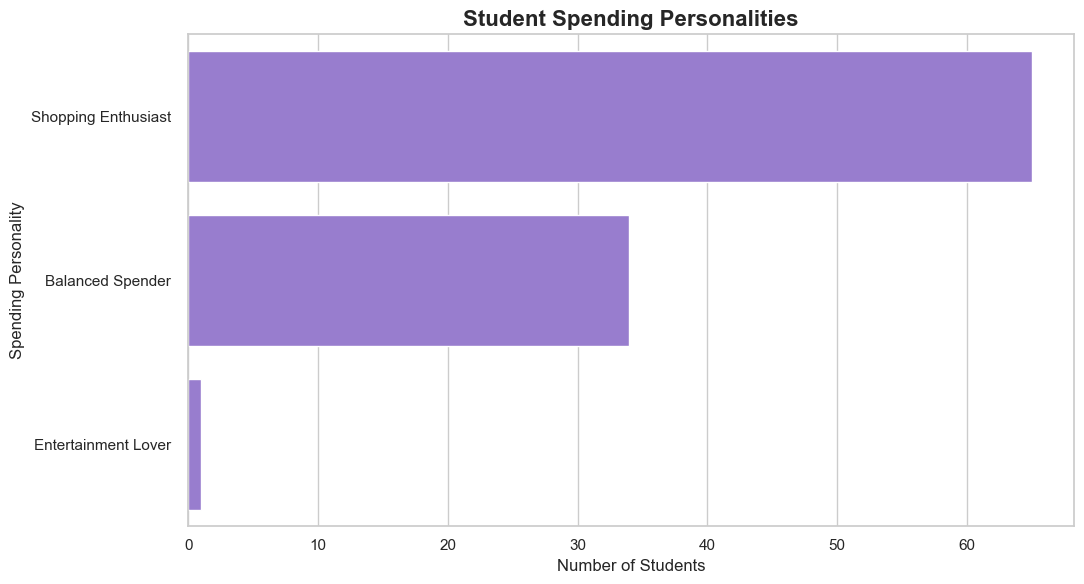

In [67]:
personality_counts = (
    category_shares["personality"]
    .value_counts()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=personality_counts.values,
    y=personality_counts.index,
    color="mediumpurple"
)

plt.title(
    "Student Spending Personalities",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Students")
plt.ylabel("Spending Personality")

plt.tight_layout()
plt.show()

In [69]:
student_summary = pd.read_csv(
    "../data/processed/student_summary.csv"
)

In [73]:
print(small_by_student.columns)

Index(['student_id', 'small_expense_total', 'small_expense_count',
       'monthly_budget'],
      dtype='object')


In [75]:
print(small_by_student.columns.tolist())

['student_id', 'small_expense_total', 'small_expense_count', 'monthly_budget']


In [77]:
small_by_student["small_budget_share"] = (
    small_by_student["small_expense_total"]
    / small_by_student["monthly_budget"]
) * 100

In [79]:
student_summary = student_summary.merge(
    small_by_student[
        ["student_id", "small_budget_share"]
    ],
    on="student_id",
    how="left"
)

student_summary["small_budget_share"] = (
    student_summary["small_budget_share"].fillna(0)
)

In [81]:
student_summary[
    ["student_id", "small_budget_share"]
].head()

,student_id,small_budget_share
0,S001,29.501479
1,S002,40.452830
2,S003,55.170807
3,S004,46.417062
4,S005,24.017331


In [83]:
personality_df = (
    category_shares[["personality"]]
    .reset_index()
)

student_summary = student_summary.merge(
    personality_df,
    on="student_id",
    how="left"
)

In [85]:
student_summary = student_summary.merge(
    first_over_budget,
    on="student_id",
    how="left"
)

In [87]:
student_summary.head()

,student_id,total_spending,monthly_budget,city,transactions,remaining_budget,over_budget,small_budget_share,personality,first_over_budget_date
0,S001,1624.19,676,Tunis,76,-948.19,True,29.501479,Shopping Enthusiast,2026-09-11
1,S002,1926.78,424,Nabeul,75,-1502.78,True,40.452830,Shopping Enthusiast,2026-09-10
2,S003,1867.68,322,Nabeul,83,-1545.68,True,55.170807,Shopping Enthusiast,2026-09-05
3,S004,1807.61,422,Sfax,71,-1385.61,True,46.417062,Shopping Enthusiast,2026-09-09
4,S005,1271.62,577,Sfax,60,-694.62,True,24.017331,Shopping Enthusiast,2026-09-10


In [89]:
student_summary.to_csv(
    "../data/processed/student_behavioral_summary.csv",
    index=False
)

print("Behavioral summary saved successfully!")

Behavioral summary saved successfully!


In [91]:
student_daily.to_csv(
    "../data/processed/student_daily_spending.csv",
    index=False
)

print("Daily spending data saved successfully!")

Daily spending data saved successfully!
